Explainabale credit risk assessment

In [3]:
#we load the data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df = pd.read_csv("/content/credit_risk_dataset.csv")

In [5]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [6]:
#we will check if the person is eligible for loan or not
#we perform some label encoding on these and do some EDA


In [7]:
df.shape

(32581, 12)

In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


In [9]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


#we check if our customer going to get the loan or not


In [10]:
df['loan_status'].unique()

array([1, 0])

In [11]:
#class imbalance is when the value of one class is more than the other
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


#this will tell us that our model will focus more towards the no value and we need to deal with it

<Axes: xlabel='loan_status', ylabel='count'>

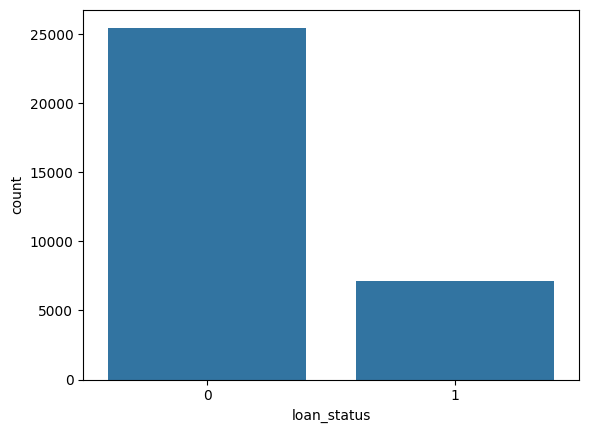

In [12]:
sns.countplot(x = 'loan_status',data = df)

In [13]:
df.describe()
#max age and person_emp_length

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


we check the outliers now

In [14]:
#create a boxplot of numeriucal columns
numerical_cols = df.select_dtypes(include = np.number).columns

In [15]:
numerical_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

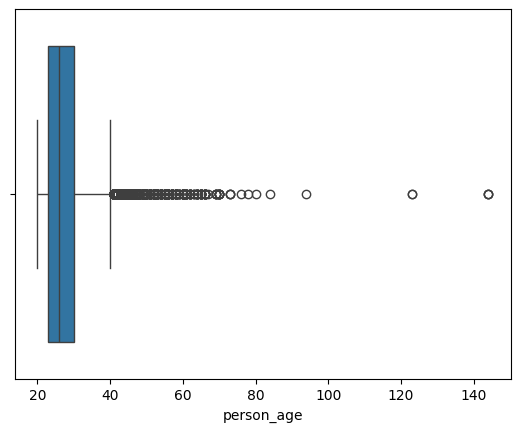

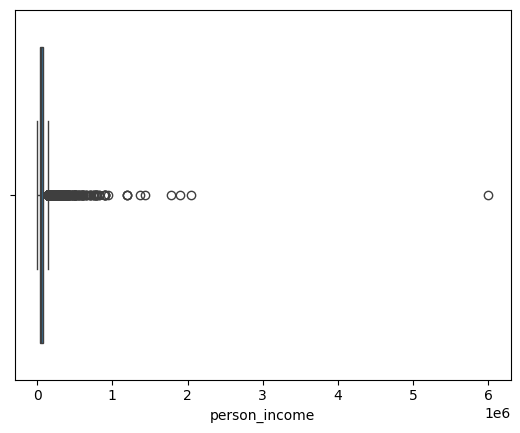

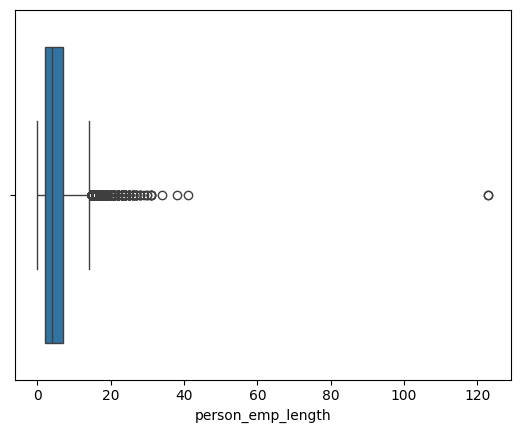

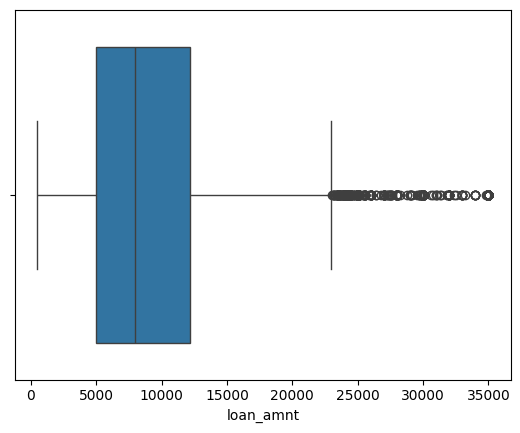

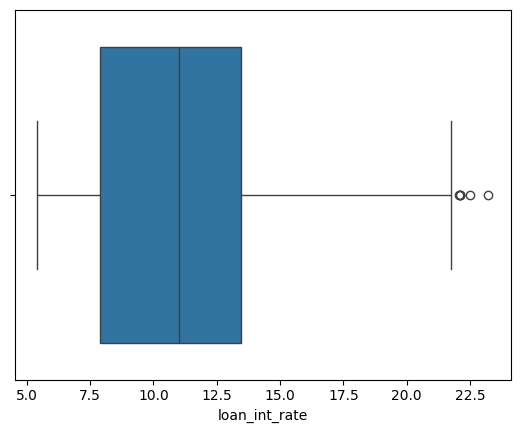

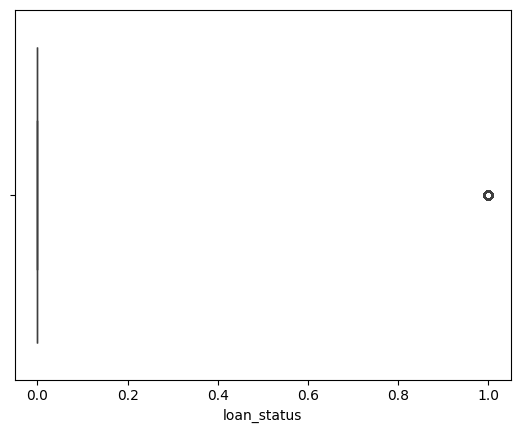

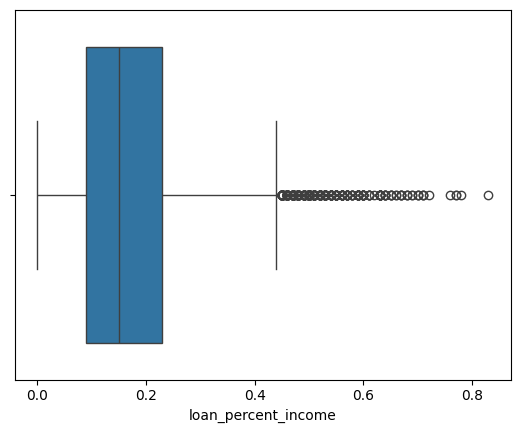

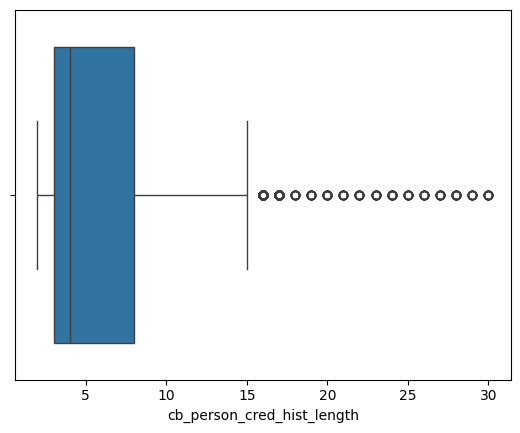

In [16]:
for i in numerical_cols:
  sns.boxplot(x = df[i]) #check for age whioch is greater than 100 as it is not possible
  plt.show()

In [17]:
(df['person_age'] > 100).sum()
# 5 people are there for ages more than 100


np.int64(5)

In [18]:
(df['person_emp_length']> 60).sum() # we check for outliers of eomployee length


np.int64(2)

We now check for correlations here

<Axes: >

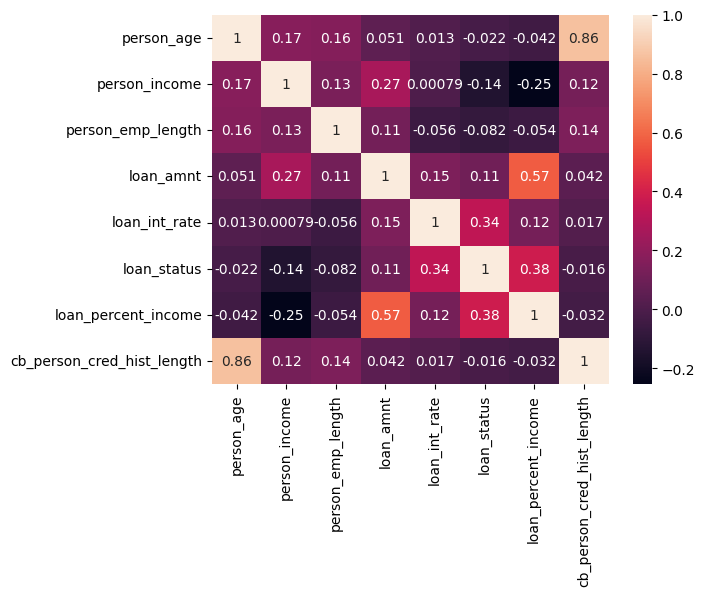

In [19]:
sns.heatmap(df.corr(numeric_only=True),annot = True)

we perform data cleaning now

In [20]:
#dealing with null values and the class imbalance
df_copy = df


In [21]:
#removing duplicate rows
print(f"rows : {df_copy.shape}")

rows : (32581, 12)


In [22]:
df_copy.drop_duplicates(inplace= True)

In [23]:
print(f"rows after removing duplicates : {df_copy.shape[0]}")

rows after removing duplicates : 32416


In [24]:
#remove ages below 18 and ages below 100
#remove employee length above 100
df_copy = df_copy[df_copy['person_age'] >= 18]
df_copy= df_copy[df_copy['person_age'] <= 100]

df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]


In [25]:
df_copy = df_copy[df_copy['person_emp_length'] <= 60]
#negative loan is also removed from here impossibvle age and work experience

df_copy = df_copy[df_copy['loan_amnt'] > 0]

In [26]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [27]:
#we check for interest rate
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [28]:
print("loan interest rate ranging from (min 5.42 to 23.22)")

loan interest rate ranging from (min 5.42 to 23.22)


FEATUERS TARGET AND TRAIN TEXT SPLIT

In [29]:
#column tarnsfoermer is usedf to prevemnt data leakage
X = df_copy.drop("loan_status",axis =1)
y = df_copy['loan_status']

In [30]:
from sklearn.model_selection import train_test_split


In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify = y)

In [32]:
#stratify = y [we have 1 and 0 and some of 1 goes to train and some to test and 0 goes to train and also to test ] it helps us to ensure the 1 and zero get equally divided

In [33]:
numerical_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file']

In [34]:
#we will handle class imbalance now as our zero was coming a lot and we have to deal with it as comparison to 1 for that ew use class - weights or smod [it works on values with less values]
#logistic regression has inbuilt class weights to handle class imbalance with "balanced mode already on in it so it focuses on teh weights"
#XG boost does not have it so we are going to make clas- wights for it

In [35]:
y_train.value_counts()

,count
loan_status,
0,19772
1,5445


In [36]:
#class - weights are calculated by dividing 0 value_counts to 1
neg, pos = np.bincount(y_train)

In [37]:
scale_weights = neg/pos

In [38]:
scale_weights

np.float64(3.6312213039485766)

In [39]:
#creating the logistic regression pipeline we need to impute here for negative values and scale our numerical features and perform one hot encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder


In [40]:
preprocessor_lr =  ColumnTransformer(
            transformers = [
                ("num",Pipeline([
                ('imputer',SimpleImputer(strategy= 'median')),
                ('scaler',StandardScaler())
                ]),numerical_cols),
                ('cat',Pipeline([
                    ('imputer',SimpleImputer(strategy = 'constant',fill_value= "Missing")),
                    ('onehot',OneHotEncoder(handle_unknown= 'ignore'))
                ]),categorical_cols)
            ]
        )


In [41]:
preprocessor_xg =  ColumnTransformer(
            transformers = [
                ("num",Pipeline([
                ('imputer',SimpleImputer(strategy= 'median'))

                ]),numerical_cols),
                ('cat',Pipeline([
                    ('imputer',SimpleImputer(strategy = 'constant',fill_value= "Missing")),
                    ('onehot',OneHotEncoder(handle_unknown= 'ignore'))
                ]),categorical_cols)
            ]
        )
#there is no scaling

In [42]:
#we will make a heloer function now
#and we wiull also perform cross validation
#our model may not give good prediction at once
#so we divide our model into 5 folds
from sklearn.model_selection import StratifiedKFold,cross_validate
cv = StratifiedKFold(n_splits = 5,shuffle = True,random_state = 42)


In [43]:
#we apply some scores now in it
scoring = {
    'roc_auc' : 'roc_auc',
    'accuracy' : 'accuracy',
    'precision' : 'precision',
    'recall' : 'recall',
    'f1': 'f1'
}

In [44]:
#now we build our model of logistic regression
from sklearn.linear_model import LogisticRegression
lr_cv_piepline = Pipeline([
   ( 'preprocessor',preprocessor_lr),
    ('model',LogisticRegression(max_iter = 1000, random_state = 42,class_weight = 'balanced'))
])

In [45]:
lr_cv_piepline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [46]:
#XGBoost model
from xgboost import XGBClassifier
xgb_cv_pipeline  =Pipeline([
    ('preprocessor',preprocessor_xg),
    ('model',XGBClassifier(n_estimators = 300,max_depth = 5, learning_rate = 0.1,scale_pos_weights = scale_weights,n_jobs = 1))
])

In [47]:
xgb_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=1,
                               num_parallel_tree=None, ...))])

In [48]:
#we train our models now
for cv_name, pipe in [("Logistic Regression",lr_cv_piepline),
                          ("XGBoost",xgb_cv_pipeline)]:
                          cv_results =cross_validate(pipe,X_train,y_train,cv = cv,scoring = scoring,n_jobs = -1)
                          print(cv_name)
                          print(f"ROC AUC : {cv_results['test_roc_auc'].mean()}")
                          print(f"accuracy : {cv_results['test_accuracy'].mean()}")
                          print(f"precision : {cv_results['test_precision'].mean()}")
                          print(f"recall : {cv_results['test_recall'].mean()}")
                          print(f"f1 : {cv_results['test_f1'].mean()}")





Logistic Regression
ROC AUC : 0.8705112830525306
accuracy : 0.8115949542892269
precision : 0.5448226008889892
recall : 0.7781450872359963
f1 : 0.6408013995933108
XGBoost
ROC AUC : 0.9476864214858469
accuracy : 0.9356387093203054
precision : 0.9635188363170112
recall : 0.7296602387511479
f1 : 0.8303608708499277


In [49]:
cv_results

{'fit_time': array([1.35469222, 1.41721487, 1.24080873, 1.27914548, 0.85916424]),
 'score_time': array([0.18491602, 0.18087411, 0.22573328, 0.24159336, 0.10772514]),
 'test_roc_auc': array([0.95129087, 0.94013065, 0.94839623, 0.94979152, 0.94882285]),
 'test_accuracy': array([0.93675654, 0.93318795, 0.93595082, 0.93654571, 0.93575253]),
 'test_precision': array([0.97297297, 0.96882793, 0.96593674, 0.95719382, 0.95266272]),
 'test_recall': array([0.72727273, 0.71349862, 0.72910927, 0.73921028, 0.73921028]),
 'test_f1': array([0.83236994, 0.82178741, 0.83097855, 0.83419689, 0.83247156])}

In [50]:
from sklearn.pipeline import Pipeline

# Correctly instantiate the baseline model pipeline
baseline_model = Pipeline([
    ('Preprocessor', preprocessor_lr),
    ('Classifier', LogisticRegression(class_weight='balanced'))
])

# Fit the corrected baseline model
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('Classifier', LogisticRegression(class_weight='balanced'))])

In [51]:
#to check performance for every model we create a common function
#it will show all the metric to us
from sklearn.metrics import confusion_matrix,classification_report,precision_recall_curve, accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
def evaluate_model(model_name,model,X_test,y_test,threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]
  if threshold is not None:
    y_pred = (y_pred_prob > threshold).astype(int)
    print(f"evaluated threshold : {threshold}")
  else:
    y_pred = model.predict(X_test)

  accuracy = accuracy_score(y_test,y_pred)
  precision = precision_score(y_test,y_pred)
  recall = recall_score(y_test,y_pred)
  f1 = f1_score(y_test,y_pred)
  cm = confusion_matrix(y_test,y_pred)
  class_report = classification_report(y_test,y_pred)
  print(f"accuracy : {accuracy : .2f}")
  print(f"precision : {precision : .2f}")
  print(f"recall : {recall : .2f}")
  print(f"f1 : {f1 : .2f}")
  print(class_report)
  print()

  #reports
  sns.heatmap(cm,annot=True,fmt="d")
  plt.title(f"{model_name} confusion_matrix")
  plt.xlabel("predicted")
  plt.ylabel("actual")
  plt.show()

  #plottting roc-auc curve
  #to show relaton between precision-recall
  precisions,recalls,thresholds = precision_recall_curve(y_test,y_pred_prob)
  plt.plot(recalls,precisions)
  plt.xlabel("recall")
  plt.ylabel("precision")
  plt.title(f"{model_name} precision-recall curve")
  plt.show()

In [52]:
#lets make our xgboost model with corrected scale_pos_weight parameter
xg_model = Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(scale_pos_weight = scale_weights,random_state = 42))
])
xg_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

accuracy :  0.82
precision :  0.56
recall :  0.79
f1 :  0.65
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305




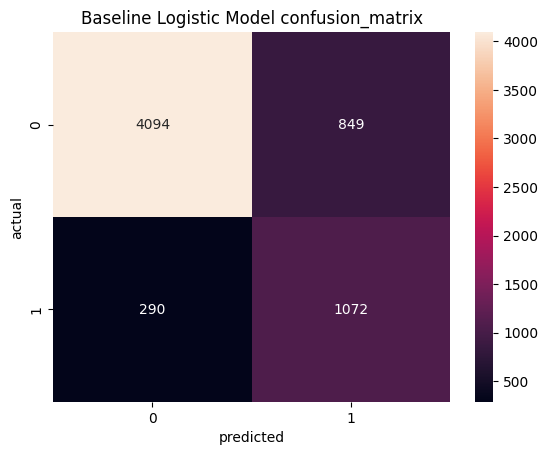

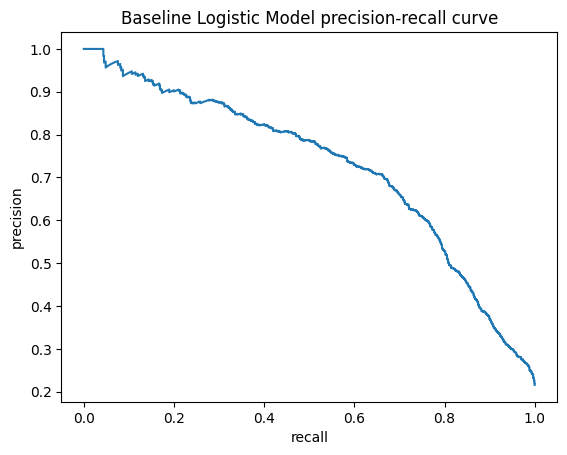

In [53]:
#evaluate the logistic model
evaluate_model("Baseline Logistic Model",baseline_model,X_test,y_test)

accuracy :  0.92
precision :  0.83
recall :  0.81
f1 :  0.82
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.83      0.81      0.82      1362

    accuracy                           0.92      6305
   macro avg       0.89      0.88      0.89      6305
weighted avg       0.92      0.92      0.92      6305




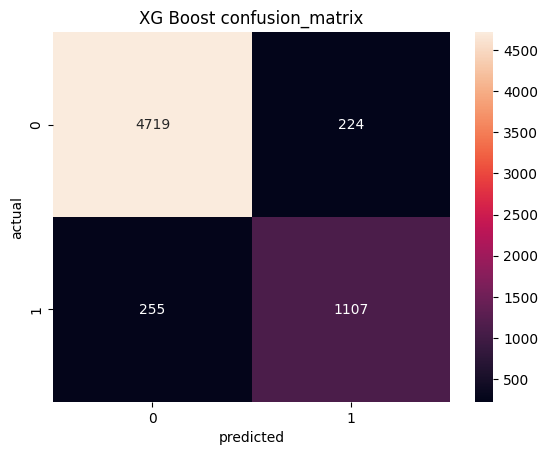

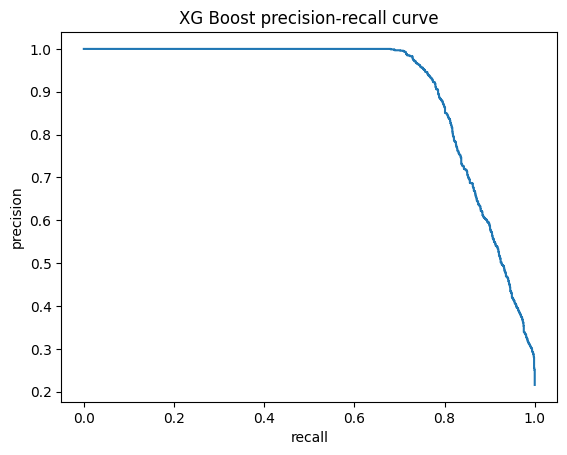

In [54]:
evaluate_model("XG Boost",xg_model,X_test,y_test)

In [55]:
#we will use randomized search cv
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# Define distribution ranges for the randomized search
param_grid = {
    "classifier__n_estimators" : randint(150, 600),
    "classifier__max_depth" : randint(3, 9),
    "classifier__learning_rate" : uniform(0.01, 0.49),
    "classifier__subsample" : uniform(0.4, 0.5), # samples uniformly between 0.4 and 0.9
    "classifier__colsample_bytree" : uniform(0.4, 0.5),
    "classifier__minimum_child_weight" : randint(1, 10),
    "classifier__gamma" : uniform(0, 5)
}

In [56]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter = 150,
    cv = cv,
    scoring = "average_precision",
    n_jobs = -1,
    verbose = 0,
    random_state = 42
)
random_search.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:51:10] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "minimum_child_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__minimum_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f37af8d0690>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f37afc23380>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7f37af8d02d0>},
                   random_state=42, scoring='average_precision')

In [57]:
print(f"score after performing tuning {random_search.best_score_:.2f}")

score after performing tuning 0.90


In [58]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.7121770240668966),
 'classifier__gamma': np.float64(1.47816842918857),
 'classifier__learning_rate': np.float64(0.0616921873168326),
 'classifier__max_depth': 6,
 'classifier__minimum_child_weight': 4,
 'classifier__n_estimators': 435,
 'classifier__subsample': np.float64(0.8416401294594342)}

accuracy :  0.82
precision :  0.56
recall :  0.79
f1 :  0.65
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305




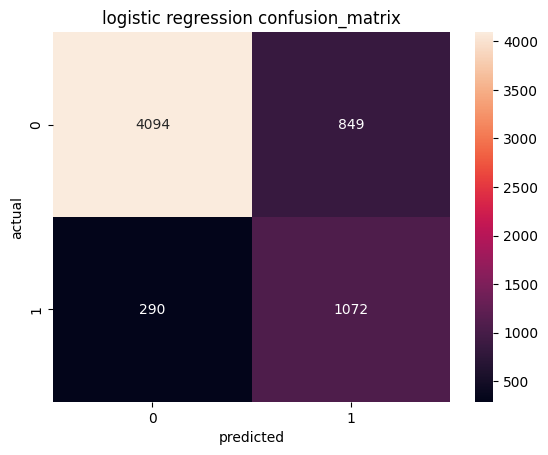

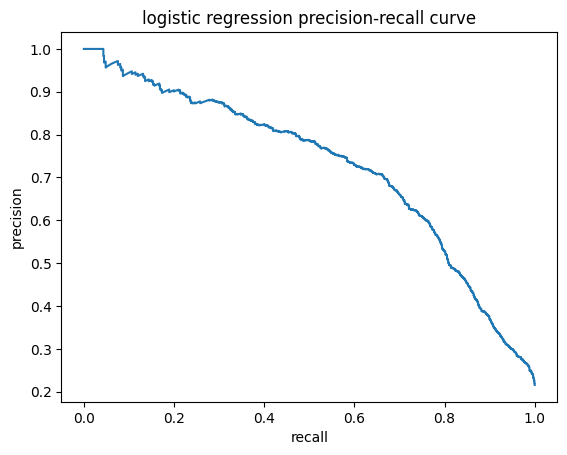

In [59]:
evaluate_model("logistic regression",baseline_model,X_test,y_test)

accuracy :  0.92
precision :  0.84
recall :  0.80
f1 :  0.82
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      4943
           1       0.84      0.80      0.82      1362

    accuracy                           0.92      6305
   macro avg       0.89      0.88      0.89      6305
weighted avg       0.92      0.92      0.92      6305




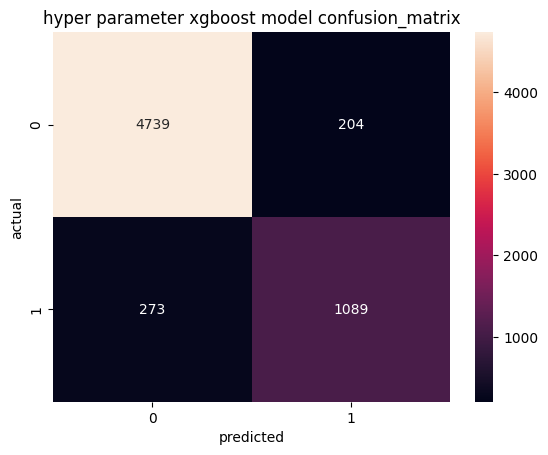

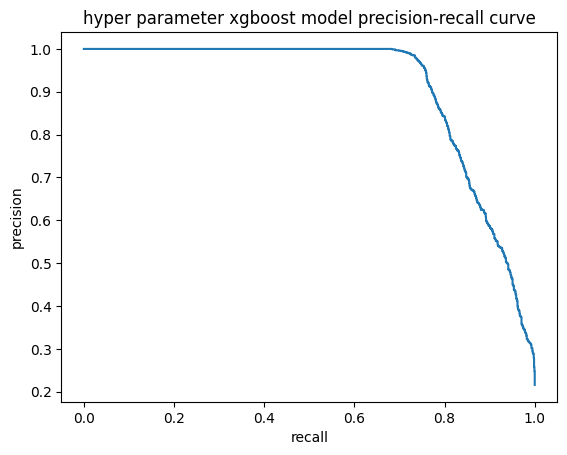

In [60]:
evaluate_model("hyper parameter xgboost model",random_search,X_test,y_test)

In [61]:
#now we will export these models
#we will also optimize the threshold
#get the probability of class 1 from xgboost

prob = xg_model.predict_proba(X_test)[:,1]

prob

#calculate precision and recall for each threshold
precisions,recalls,thresholds = precision_recall_curve(y_test,prob)
thresholds


#calculate the f1 score now (corrected to multiplication)
f1 = 2*(precisions*recalls)/(precisions + recalls + 1e-9)
f1

#get the threshold with the highest f1 score
#we use argmax
best = np.argmax(f1[:-1])

#now we need the threshold value where it produces it
best_threshold = thresholds[best]

evaluated threshold : 0.6448367834091187
accuracy :  0.94
precision :  0.92
recall :  0.78
f1 :  0.84
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      4943
           1       0.92      0.78      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.93      0.88      0.90      6305
weighted avg       0.94      0.94      0.94      6305




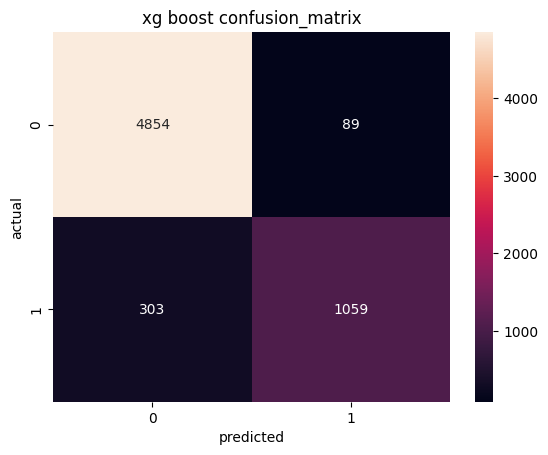

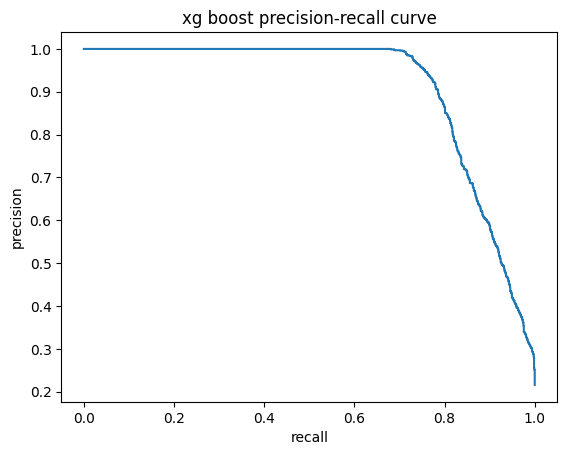

In [62]:
#now we evaluate it
evaluate_model("xg boost",xg_model,X_test,y_test,best_threshold)

In [63]:
#probability calliberation
#SHAP interpretation - Global and local
#shap helps us to understand why a model make certain decisions it is a way to explain the black box model

In [64]:
#lets start with probability calliberation
#80 percent probability mean that the prediction must be 80 detected spams are true and 20 are not spam
#un caliberation is 80 percent not spam and 20 percent spam and it is important to understand
# if model prediction is 80 percent spam and actual is 82 out of 100
#so we make a graph of predicted vs actual probability of values

In [65]:
"""
there are a lot of methods to fix poor callibration
1.Platt scaling / use sigmoid activation function to adjust the probabiliy using a sigmoid function which is good for small data
2.Isotonic regression-> learns a flexible mapping from old probability to a better one(good for non linear)
3.Temperature scaling -> adjust the confidence of neural network predictions



"""

'\nthere are a lot of methods to fix poor callibration\n1.Platt scaling / use sigmoid activation function to adjust the probabiliy using a sigmoid function which is good for small data\n2.Isotonic regression-> learns a flexible mapping from old probability to a better one(good for non linear)\n3.Temperature scaling -> adjust the confidence of neural network predictions\n\n\n\n'

In [66]:
#1 calibrate our model
from sklearn.calibration import CalibratedClassifierCV,calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(best_model,cv =cv, n_jobs = -1,method = 'sigmoid')
calibrated_model.fit(X_train,y_train)




#get probabilities
#create caliberation curves
#plot

CalibratedClassifierCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_le...
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.0616921873168326),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=None,
                                                                minimum_child_weight=4,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=435,
                                                                n_jobs=None, ...))]),
                       n_jobs=-1)

In [67]:
#lets get the calibrated probabilities
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [68]:
calibrated

array([0.62985416, 0.02808032, 0.9536292 , ..., 0.47150903, 0.02454593,
       0.01505941], shape=(6305,))

In [69]:
uncalibrated

array([0.7660541 , 0.13431093, 0.98424584, ..., 0.64911723, 0.00859273,
       0.00537985], shape=(6305,), dtype=float32)

In [70]:
#create the calibrated curves
actual_uncalibrated,predicted_uncalibrated = calibration_curve(y_test,uncalibrated,n_bins = 10)
actual_calibrated,predicted_calibrated = calibration_curve(y_test,calibrated,n_bins = 10)

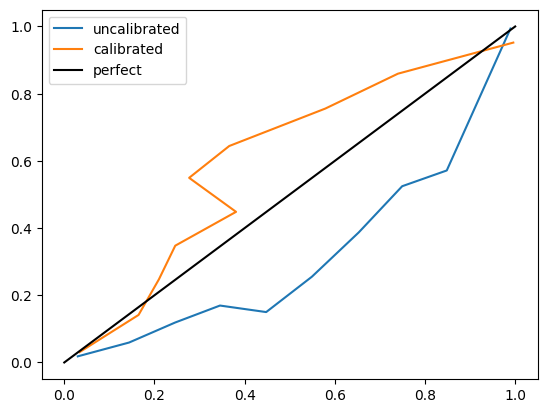

In [71]:
plt.plot(predicted_uncalibrated,actual_uncalibrated,label = "uncalibrated")
plt.plot(actual_calibrated,predicted_calibrated,label = 'calibrated')
plt.plot([0,1],[0,1],'k-',label = 'perfect')
#not good for our data
plt.legend()


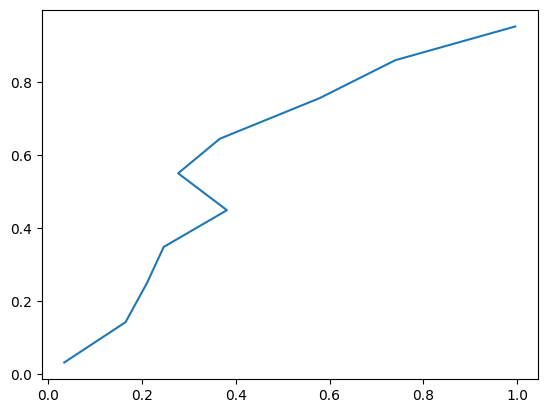

In [72]:
plt.plot(actual_calibrated,predicted_calibrated,label = 'calibrated')

In [73]:
#we need to draw a straight line for it and which model to pick
#we pick the calibrated model here




In [74]:
#lets start with the shap interpretation
#shap tells us how and which inputs help us to make better models
#it tells us the contribution of each and every feature in the output prediction [it can increase or decrease]
#global and local explanation
#local explantions-> why did the model make this prediction for this student? it breaks down the score feature by feature
#shap is used for pca to reduce dimensions
#global explanations->  which features are generally that are the most important to the model?


In [75]:
#1 install shap if not exists
!pip install shap

In [76]:
import shap

In [77]:
#2 get the trained xgboost classifier out of the pipeline
xgb_classifier = xg_model.named_steps['classifier']
xgb_classifier


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [78]:
#3 transform x_test using the same preprocessing used for training
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)



In [79]:
#4 get feature names after one hot encoding so plots are readable
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [80]:
#5 convert the categorical features into cleaner SHAP plots

In [81]:
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [82]:
#create SHAP explainer for tree based model
explainer = shap.TreeExplainer(xgb_classifier)

In [83]:
#7 calculate shap values for every row in the test set
shap_values = explainer.shap_values(X_test_df)

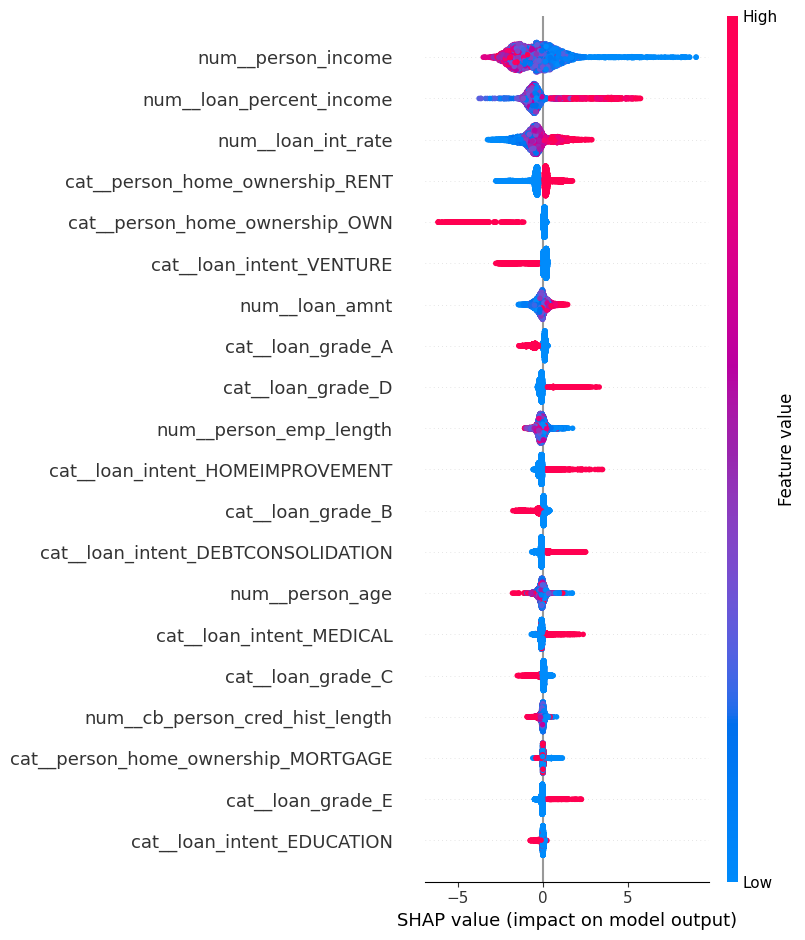

In [84]:
#check for global explanations
#which are the most important features
#inreasing and decreasing of risk
shap.summary_plot(shap_values,X_test_df)

In [85]:
#local explanation
#why the output got that prediction
#pick one row to explain

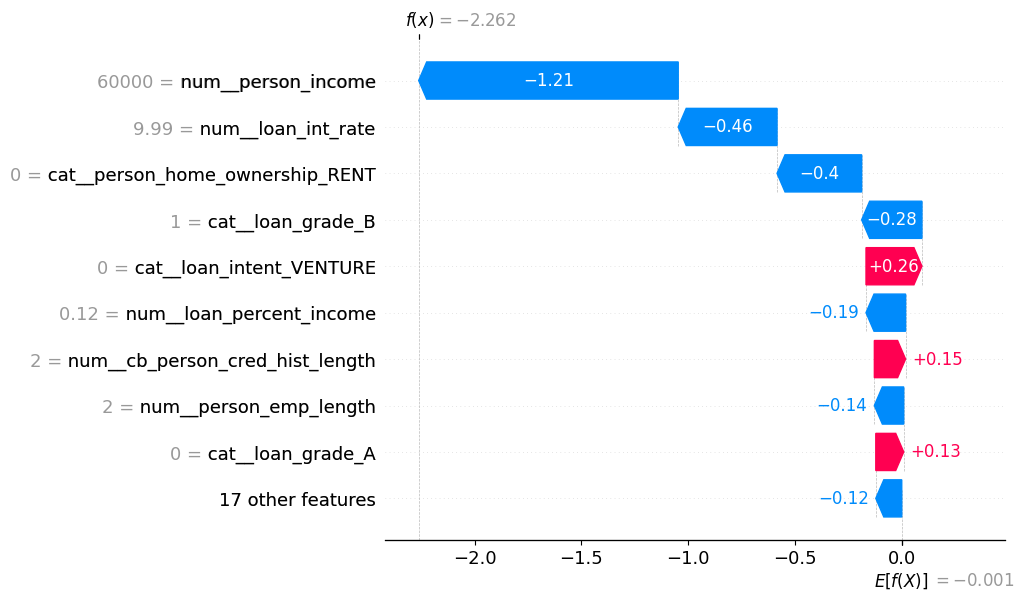

In [86]:
row_index = 5

#2 draw a waterfall plot showing how each feature push the prediction up or down
shap.waterfall_plot(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

In [87]:
#analyzing false positives and false negatives
y_pred = random_search.predict(X_test)

In [88]:
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [89]:
false_positive = (result_df['actual'] == 0) & (result_df['predicted'] == 1)
false_negative = (result_df['actual'] == 1) & (result_df['predicted'] == 0)

In [90]:
print(f"False positives : {false_positive.sum()}")
print(f"False negatives : {false_negative.sum()}")

False positives : 204
False negatives : 273


In [91]:
#lets export this model using joblib
import joblib
#to import our file into pkl we dump it
joblib.dump(calibrated_model,'calibrated_model.pkl')


['calibrated_model.pkl']

In [98]:
joblib.dump(best_threshold,'best_threshold.pkl')

['best_threshold.pkl']

In [96]:
from sklearn.metrics import precision_recall_curve
import numpy as np

calibrated_proba = calibrated_model.predict_proba(X_test)[:,1]
precision,recall,threshold = precision_recall_curve(y_test,calibrated_proba)
f1_score = 2*(precision*recall)/(precision + recall + 1e-9)
best_threshold = threshold[np.argmax(f1_score[:-1])]
print(f"best threshold : {best_threshold}")

best threshold : 0.6789528935582195
